# 06 · Support Vector Machine for Regression (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` (regression, ឯកតា $100,000)

## 1. Goal
ប្រើ **Support Vector Regression (SVR)**: ជា SVM កំណែ regression ដែលអាចរៀនទំនាក់ទំនង **កោង** ដោយប្រើ **kernel**។ ដូចជា KNN វាត្រូវការ scaling ហើយវាមាន hyperparameters (`C`, `gamma`) ដែលត្រូវ tune។
នេះក៏ជាឱកាសមើល **ដែនកំណត់ជាក់ស្តែង**: SVR យឺតខ្លាំងនៅពេល data កើនធំ។

## Concept
- **Classification SVM** (Titanic/breast cancer) រក hyperplane ដែលមាន **margin ធំបំផុត** រវាង classes។
- **SVR** ត្រឡប់គំនិតនេះ: វារកអនុគមន៍ដែលស្ថិតនៅក្នុង **ទុយោ (tube)** ទទឹង `±epsilon` ជុំវិញចំណុចទិន្នន័យ។
  - **ចំណុចដែលនៅក្នុង tube** → ចាត់ទុកថាគ្មានកំហុស (កំហុសតូចជាង `epsilon` ត្រូវបានអត់ឱន; លំនាំដើម `epsilon = 0.1` = $10,000)។
  - **ចំណុចដែលនៅក្រៅ tube** ដាក់ពិន័យ។ មានតែចំណុចទាំងនេះ (និងចំណុចនៅលើគែម) ទេដែលកំណត់ model ហៅថា **support vectors**។

**ឧបមា "អត់ឱនក្នុងកម្រិតកំហុសតូច":** ម្ចាស់ហាងដែលពិនិត្យតម្លៃ មិនខ្វល់បើតម្លៃខុស ±$10,000 ទេ គាត់ខ្វល់តែតម្លៃដែលខុសច្រើនជាងនេះ។ ដូច្នេះគាត់ផ្តោតលើករណី "ដែលខុស" ហើយមិនខ្វល់ករណីធម្មតា។

**`C`** = ភាពតឹងរ៉ឹងចំពោះចំណុចក្រៅ tube: `C` តូច = អត់ឱនកំហុសច្រើន (model រលោង, simple, ងាយ underfit); `C` ធំ = ព្យាយាមតាមចំណុចទាំងអស់ (model កោងច្រើន, ងាយ overfit)។
**Kernel `rbf`** អនុញ្ញាតឲ្យ model ជាខ្សែកោង។ **`gamma`** កំណត់ថាចំណុចមួយមានឥទ្ធិពលទៅដល់ចម្ងាយប៉ុនណា: `gamma` ធំ = ឥទ្ធិពលតូច (ខ្សែកោងរមួល, overfit), `gamma` តូច = ឥទ្ធិពលធំ (ខ្សែកោងរលោង)។

Import libraries។

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

def evaluate(model, A, B):
    """Train and test MAE / RMSE / R2 for a fitted model. A = train features, B = test features."""
    out = {}
    for split, Xs, ys in [("train", A, y_train), ("test", B, y_test)]:
        pred = model.predict(Xs)
        out[f"{split} MAE"] = mean_absolute_error(ys, pred)
        out[f"{split} RMSE"] = np.sqrt(mean_squared_error(ys, pred))
        out[f"{split} R2"] = r2_score(ys, pred)
    return out

Load clean data ហើយ split ដូច Lesson 2 (`test_size=0.2`, `random_state=42`)។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 2. 2D visual: the tube, support vectors and C
ដើម្បីមើលដោយភ្នែក យើងប្រើ feature តែមួយ (`MedInc`) និងគំរូតូច 300 rows ពី training set។ ប្រើ `epsilon = 0.5` (ធំជាងលំនាំដើម) ដើម្បីឲ្យ tube មើលឃើញច្បាស់។
បន្ទាត់ពណ៌ទឹកក្រូច = model; បន្ទាត់ដាច់ៗ = គែមរបស់ tube; រង្វង់ទឹកក្រូច = **support vectors**។

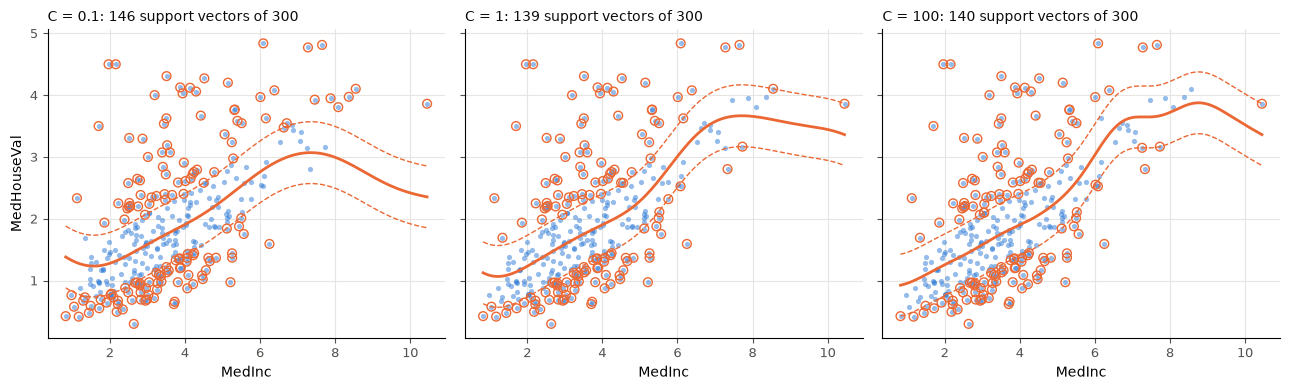

In [3]:
rng = np.random.RandomState(1)
sub = rng.choice(len(X_train), 300, replace=False)
x_sub = X_train.iloc[sub][["MedInc"]].to_numpy()
y_sub = y_train.iloc[sub].to_numpy()
grid = np.linspace(x_sub.min(), x_sub.max(), 300).reshape(-1, 1)
EPS = 0.5

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, c_value in zip(axes, [0.1, 1, 100]):
    m = SVR(kernel="rbf", C=c_value, epsilon=EPS).fit(x_sub, y_sub)
    line = m.predict(grid)
    ax.scatter(x_sub, y_sub, s=14, color=BLUE, alpha=0.5, linewidth=0)
    ax.scatter(x_sub[m.support_], y_sub[m.support_], s=40, facecolors="none", edgecolors=ORANGE, linewidths=1)
    ax.plot(grid, line, color=ORANGE, linewidth=2)
    ax.plot(grid, line + EPS, color=ORANGE, linewidth=1, linestyle="--")
    ax.plot(grid, line - EPS, color=ORANGE, linewidth=1, linestyle="--")
    ax.set_title(f"C = {c_value}: {len(m.support_)} support vectors of 300", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("MedInc"); style(ax)
axes[0].set_ylabel("MedHouseVal")
fig.tight_layout()
plt.show()

**អានក្រាហ្វ:**
- បន្ទាត់ទឹកក្រូច (model) ជាខ្សែកោង **រលោង** ឡើងតាម `MedInc` ហើយ tube (ដាច់ៗ) ស្ថិតនៅជុំវិញវា។ **រង្វង់ទឹកក្រូច = support vectors** គឺជាចំណុចនៅក្រៅ ឬលើគែម tube ដែលជាអ្នកកំណត់ model។ ចំណុចខាងក្នុង tube មិនប៉ះពាល់ model ទេ។
- **`C = 0.1`** (អត់ឱនកំហុស): ខ្សែកោង **រាបស្មើ** ជាង កើនឡើងទៅត្រឹម ≈ 3.1 ហើយ underfit សម្រាប់សង្កាត់ចំណូលខ្ពស់។ **`C = 1` និង `C = 100`**: ខ្សែកោងចោតជាង និងឡើងដល់ ≈ 3.7–4.1 ដោយតាមចំណុចជាង។
- ពីរផ្នែកនេះប្រែប្រួល **តិចតួច** ពី C = 1 ទៅ C = 100 ព្រោះ data មាន noise ច្រើន (សង្កាត់ដែលមានចំណូលដូចគ្នា តម្លៃខុសគ្នាច្រើន) ហើយ feature តែមួយមិនអាចពន្យល់បាន។ ចំនួន support vectors ស្ទើរតែដូចគ្នា (146, 139, 140 ក្នុង 300) ព្រោះប្រហែលពាក់កណ្តាលនៃចំណុចនៅក្រៅ tube ទោះ C ប៉ុនណា។
- ក្នុង data ពិត support vectors គឺជាសមាមាត្រធំនៃ training rows (មើល Step 6)។

## 3. Why scaling is mandatory
Kernel `rbf` គណនា distance រវាងចំណុច ដូច KNN ដូច្នេះ `Population` (រាប់ពាន់) នឹងគ្រប់គ្រង `MedInc` (រាប់ឯកតា) ប្រសិនបើមិន scale។
SVR យឺត ដូច្នេះសម្រាប់ការបង្ហាញនេះប្រើគំរូ 3,000 rows ពី training set (ប៉ុន្តែវាយតម្លៃលើ test set ទាំងមូល)។
ប្រើ `Pipeline` ដើម្បីឲ្យ scaler `fit` លើ training rows តែប៉ុណ្ណោះ។

In [4]:
sub_idx = X_train.sample(3000, random_state=42).index
svr_unscaled = SVR().fit(X_train.loc[sub_idx], y_train.loc[sub_idx])
svr_scaled = Pipeline([("scaler", StandardScaler()), ("svr", SVR())]).fit(X_train.loc[sub_idx], y_train.loc[sub_idx])
pd.DataFrame({
    "unscaled": {"test R2": r2_score(y_test, svr_unscaled.predict(X_test)),
                 "test RMSE": np.sqrt(mean_squared_error(y_test, svr_unscaled.predict(X_test)))},
    "scaled (Pipeline)": {"test R2": r2_score(y_test, svr_scaled.predict(X_test)),
                          "test RMSE": np.sqrt(mean_squared_error(y_test, svr_scaled.predict(X_test)))},
}).T.round(3)

,test R2,test RMSE
unscaled,-0.029,0.993
scaled (Pipeline),0.718,0.519


**អានលទ្ធផល:** Scaling ផ្លាស់ប្តូរអ្វីៗទាំងអស់: test R² លោតពី **−0.029** (មិន scale) ទៅ **0.718** (scale)។ ដោយមិន scale, SVR **អន់ជាង baseline** (R² ≈ 0): `Population` (រាប់ពាន់) គ្រប់គ្រង distance ហើយ kernel មិនឃើញ `MedInc` ឬទីតាំង។
ក្នុង Lessons 3 (KNN) និង 6 (SVR) វាជាច្បាប់ដូចគ្នា: **models ដែលប្រើ distance ត្រូវការ scaling ជានិច្ច**។ Trees មិនត្រូវការ។ ចំណាំ: ក្នុង Step 3 នេះ SVR ប្រើតែ 3,000 rows (មិនទាន់ tune) ដូច្នេះ R² 0.718 មិនទាន់ជាពិន្ទុចុងក្រោយទេ។

## 4. Tune C and gamma with GridSearchCV (training set only)
`GridSearchCV` សាកល្បងគ្រប់បន្សំនៃ hyperparameters ដោយ **3-fold Cross-Validation លើ training set តែប៉ុណ្ណោះ** ហើយ test set មិនត្រូវបានប៉ះទេ។
Scaler នៅក្នុង `Pipeline` ដូច្នេះវា `fit` ឡើងវិញលើ training folds ក្នុងរាល់ fold (គ្មាន leakage)។
`scoring="neg_root_mean_squared_error"`: sklearn ចាត់ទុក "ខ្ពស់ជាង = ល្អជាង" ដូច្នេះ RMSE ត្រូវបានដាក់ជាអវិជ្ជមាន។ ការស្វែងរកនេះប្រើ CPU ទាំងអស់ ហើយអាចចំណាយពេលមួយទៅពីរនាទី។

In [5]:
pipe = Pipeline([("scaler", StandardScaler()), ("svr", SVR())])
param_grid = {"svr__C": [1, 3, 10, 30], "svr__gamma": [0.03, 0.1, 0.3]}
search = GridSearchCV(pipe, param_grid, cv=KFold(n_splits=3, shuffle=True, random_state=42),
                      scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X_train, y_train)
search.best_params_

{'svr__C': 3, 'svr__gamma': 0.3}

តារាង CV RMSE (មធ្យមលើ 3 folds; ទាបជាង = ល្អជាង)។

In [6]:
cv_results = pd.DataFrame(search.cv_results_)
cv_results["CV RMSE"] = -cv_results["mean_test_score"]
cv_results["std"] = cv_results["std_test_score"]
cv_results.pivot(index="param_svr__C", columns="param_svr__gamma", values="CV RMSE").round(4)

param_svr__gamma,0.03,0.10,0.30
param_svr__C,,,
1,0.5294,0.5058,0.4943
3,0.5220,0.4989,0.4928
10,0.5152,0.4957,0.5020
30,0.5103,0.4976,0.5227


In [7]:
best_row = cv_results.loc[search.best_index_]
{"best CV RMSE": round(float(best_row["CV RMSE"]), 4), "std across folds": round(float(best_row["std"]), 4),
 "worst CV RMSE in grid": round(float(cv_results["CV RMSE"].max()), 4)}

{'best CV RMSE': 0.4928,
 'std across folds': 0.0011,
 'worst CV RMSE in grid': 0.5294}

**អានលទ្ធផល:**
- **Hyperparameters ល្អបំផុត: `C = 3`, `gamma = 0.3`** ដែលមាន CV RMSE **0.4928** (std ក្នុងចន្លោះ folds ត្រឹម 0.0011)។ បន្សំអន់បំផុត (`C = 1`, `gamma = 0.03`) មាន 0.5294។
- **គំរូនៃ trade-off:** ជួរ `gamma = 0.03` (ខ្សែកោងរលោង) ប្រសើរឡើងបន្តិចម្តងៗពេល C កើន (0.5294 → 0.5103): model រលោងពេក underfit ត្រូវការ C ធំជាង។ ជួរ `gamma = 0.3` (ខ្សែកោងរមួល)
  ផ្ទុយ: C ធំជាង overfit (0.4943 → 0.5227 ពី C = 1 ដល់ 30)។ `C` និង `gamma` ដំណើរការ **ជាមួយគ្នា**។
- ⚠️ **ល្អបំផុតស្ថិតនៅគែមនៃ grid** សម្រាប់ `gamma` (0.3 ជាតម្លៃធំបំផុតដែលសាកល្បង)។ ដូច្នេះ grid ធំជាងនេះអាចរកឃើញពិន្ទុល្អជាងបន្តិច។ វាជាមូលហេតុមួយដែលមេរៀន 8 ប្រើ random search លើចន្លោះធំជាង។
- គម្លាតពី 0.4928 ដល់ 0.5294 តូច (7%): SVR មិនប្រកាន់ hyperparameters ខ្លាំងពេកទេ ប៉ុន្តែការ tune នៅតែជួយ។

## 5. Final model on the test set
`search.best_estimator_` ត្រូវបាន train ឡើងវិញលើ training set ទាំងមូល (15,546 rows) ដោយប្រើ hyperparameters ល្អបំផុត។ ឥឡូវនេះ **បើក test set ម្តង**។

In [8]:
svr = search.best_estimator_
pd.DataFrame({"SVR (tuned, Pipeline)": evaluate(svr, X_train, X_test)}).T.round(3)

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
"SVR (tuned, Pipeline)",0.269,0.415,0.817,0.328,0.477,0.762


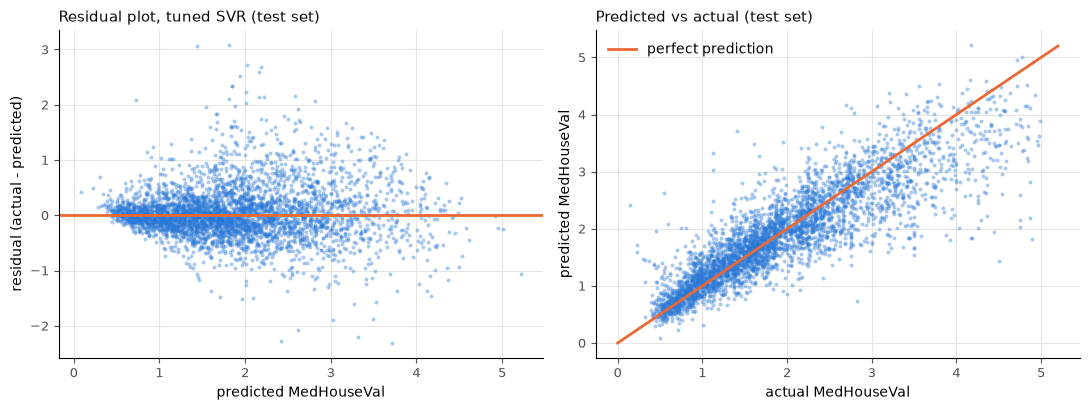

In [9]:
pred_test = svr.predict(X_test)
resid = y_test - pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(pred_test, resid, s=8, color=BLUE, alpha=0.4, linewidth=0)
ax1.axhline(0, color=ORANGE, linewidth=2)
ax1.set_xlabel("predicted MedHouseVal"); ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title("Residual plot, tuned SVR (test set)", loc="left", fontsize=11, color=INK); style(ax1)

ax2.scatter(y_test, pred_test, s=8, color=BLUE, alpha=0.4, linewidth=0)
lims = [0, 5.2]
ax2.plot(lims, lims, color=ORANGE, linewidth=2, label="perfect prediction")
ax2.set_xlabel("actual MedHouseVal"); ax2.set_ylabel("predicted MedHouseVal")
ax2.set_title("Predicted vs actual (test set)", loc="left", fontsize=11, color=INK)
ax2.legend(frameon=False); style(ax2)
fig.tight_layout()
plt.show()

**អានលទ្ធផល:** SVR (tuned) លើ test set: **MAE 0.328, RMSE 0.477, R² 0.762**។
- Test RMSE (0.477) **ទាបជាង** CV RMSE (0.4928) បន្តិច។ នេះមិនមែនជាសំណាងទេ: CV train លើ 2/3 នៃ training set (≈ 10,400 rows) ប៉ុន្តែ model ចុងក្រោយ train លើ rows ទាំងអស់ (15,546)។ SVR ប្រសើរឡើងជាមួយ data ច្រើនជាង (មើល Step 6: R² កើនពី 0.664 ទៅ 0.762 ពេល rows កើនពី 1,000 ទៅ 15,546)។
- **Train R² 0.817 ទល់ test 0.762**: គម្លាតតូច → overfit តិច។
- **Predicted vs actual:** ចំណុចជិតបន្ទាត់ជាង Linear, KNN និង tree ហើយ model នេះរលោង (ខ្សែកោងបន្ត មិនមែនជាជណ្តើរ)។ ប៉ុន្តែសម្រាប់សង្កាត់ថ្លៃបំផុត (actual > 3.5) ចំណុចភាគច្រើននៅក្រោមបន្ទាត់ ម្តងទៀត។ Residual plot នៅតែមានរាងចីវលោ។

## 6. The real limit of SVR: training time grows fast with the number of rows
SVR ត្រូវគណនា kernel រវាងគូនៃចំណុច ដូច្នេះពេលវេលា train កើនឡើង **លឿនជាងសមាមាត្រ** នឹងចំនួន rows។ សាកល្បង train ជាមួយចំនួន rows ខុសៗគ្នា (hyperparameters ល្អបំផុត)
ហើយវាស់ពេល។ (លេខវិនាទីអាស្រ័យលើកុំព្យូទ័ររបស់អ្នក; អ្វីដែលសំខាន់គឺ **របៀបដែលវាកើនឡើង**។)

In [10]:
best = search.best_params_
rows = []
for n in [1000, 2000, 4000, 8000, len(X_train)]:
    idx = X_train.sample(n, random_state=42).index
    m = Pipeline([("scaler", StandardScaler()), ("svr", SVR(C=best["svr__C"], gamma=best["svr__gamma"]))])
    start = time.perf_counter()
    m.fit(X_train.loc[idx], y_train.loc[idx])
    rows.append({"training rows": n, "fit seconds": time.perf_counter() - start,
                 "support vectors": int(m.named_steps["svr"].support_.shape[0]), "test R2": m.score(X_test, y_test)})
pd.DataFrame(rows).set_index("training rows").round(3)

,fit seconds,support vectors,test R2
training rows,,,
1000,0.065,822,0.664
2000,0.224,1591,0.701
4000,0.878,3077,0.730
8000,3.532,6053,0.747
15546,13.453,11527,0.762


**អានលទ្ធផល:**
- ពេល train កើនលឿនជាង rows ច្រើន: ក្នុង run នេះពេលកើន **ប្រហែល 4 ដង រាល់ពេលដែល rows កើនទ្វេដង** (ឧ. 4,000 → 8,000 rows: ≈ 0.9 → 3.6 វិនាទី, 8,000 → 15,546: 3.6 → 13.5 វិនាទី)។
  សម្រាប់ data រាប់លាន rows SVR នឹងមិនអាចប្រើបាន។ (Random Forest និង XGBoost កើនស្ទើរតែ **ជាលីនេអ៊ែរ** តាមចំនួន rows។)
- **Support vectors ជាសមាមាត្រធំ**: 11,527 ក្នុង 15,546 rows (≈ 74%) ជាផ្នែកនៃ model។ ពេលទាយ SVR ត្រូវគណនា kernel ទៅ support vectors ទាំងនោះ ដូច្នេះការទាយក៏យឺតដែរ (ដូច KNN)។
- ពិន្ទុ test **នៅតែប្រសើរឡើង** ជាមួយ rows ច្រើនជាង (0.664 → 0.762) ដូច្នេះបន្ថែម data ជួយ ប៉ុន្តែតម្លៃកើនលឿន។

## 7. Comparison with earlier models
Split ដដែល។ Linear Regression, KNN និង SVR ប្រើ scaling (fit លើ train តែប៉ុណ្ណោះ); trees និង forests ប្រើ data ដើម។

In [11]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
forest = RandomForestRegressor(n_estimators=300, max_features=0.5, random_state=42, n_jobs=-1).fit(X_train, y_train)

comparison = pd.DataFrame({
    "Baseline (mean)": evaluate(DummyRegressor(strategy="mean").fit(X_train_s, y_train), X_train_s, X_test_s),
    "Linear Regression": evaluate(LinearRegression().fit(X_train_s, y_train), X_train_s, X_test_s),
    "KNN (k=15)": evaluate(KNeighborsRegressor(n_neighbors=15).fit(X_train_s, y_train), X_train_s, X_test_s),
    "Tree (max_depth=9)": evaluate(DecisionTreeRegressor(max_depth=9, random_state=42).fit(X_train, y_train), X_train, X_test),
    "Random Forest (300 trees, max_features=0.5)": evaluate(forest, X_train, X_test),
    "SVR (tuned)": evaluate(svr, X_train, X_test),
}).T.round(3)
comparison

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
Baseline (mean),0.779,0.971,0.000,0.790,0.979,-0.000
Linear Regression,0.438,0.587,0.634,0.439,0.590,0.636
KNN (k=15),0.354,0.498,0.737,0.380,0.535,0.701
Tree (max_depth=9),0.324,0.462,0.774,0.385,0.561,0.671
"Random Forest (300 trees, max_features=0.5)",0.110,0.164,0.972,0.295,0.441,0.797
SVR (tuned),0.269,0.415,0.817,0.328,0.477,0.762


**អានលទ្ធផល:**
- **SVR (tuned)** ល្អជាង Linear (0.636), KNN (0.701) និង tree (0.671): **R² 0.762, MAE 0.328, RMSE 0.477**។
- ប៉ុន្តែ **Random Forest នៅតែឈ្នះ** (R² 0.797, MAE 0.295, RMSE 0.441) ហើយរហ័សជាងច្រើន (train 15,546 rows ក្នុងប៉ុន្មានវិនាទី) និងត្រូវការ tuning តិចជាង។
- SVR ខ្លាំងជាងលើ data **តូច** (1,000–5,000 rows) និងពេលទំនាក់ទំនងរលោង ប៉ុន្តែលើ data ធំ tabular ដូចនេះ ក្រុម trees (forest, boosting) ជាធម្មតាល្អជាង ហើយលឿនជាង។
- ភាពខុសគ្នា SVR ទល់ forest (0.035 R²) ពិតប្រាកដ (3,887 test rows) ប៉ុន្តែតូចជាងភាពខុសគ្នារវាង Linear ទល់ SVR (0.126)។

## 8. Predict for the two made-up neighbourhoods
`svr` ជា `Pipeline` ដូច្នេះវា scale data ថ្មីដោយខ្លួនឯង (ប្រើ mean/std ពី training) យើងបញ្ជូន data **ដើម** ត្រង់ៗ។

In [12]:
new_neighbourhoods = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500,
     "AveOccup": 2.8, "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800,
     "AveOccup": 3.4, "Latitude": 36.75, "Longitude": -119.80},
], index=["high income, Los Angeles coast", "low income, inland Central Valley"])
pd.DataFrame({
    "price (SVR)": svr.predict(new_neighbourhoods).round(2),
    "price (Random Forest)": forest.predict(new_neighbourhoods).round(2),
    "price (Linear Regression)": LinearRegression().fit(X_train_s, y_train).predict(scaler.transform(new_neighbourhoods)).round(2),
}, index=new_neighbourhoods.index)

,price (SVR),price (Random Forest),price (Linear Regression)
"high income, Los Angeles coast",3.96,4.07,3.77
"low income, inland Central Valley",0.60,0.59,0.96


**អានលទ្ធផល:** SVR ទាយ Los Angeles = **3.96** ($396,000) និង Central Valley = **0.60** ($60,000) ជិតខ្លាំងនឹង Random Forest (4.07 និង 0.59) ហើយខុសពី Linear (3.77 និង 0.96)។ Models ទាំងពីរដែលអាចចាប់ទំនាក់ទំនងមិនត្រង់ យល់ស្របគ្នា ខណៈ Linear មិនអាច (ពិសេស Central Valley ដែល Linear ទាយខ្ពស់ពេក)។

## Lesson summary
- **SVR** រកអនុគមន៍ក្នុង **tube** ទទឹង `±epsilon` (លំនាំដើម 0.1 = $10,000)។ កំហុសក្នុង tube មិនត្រូវបានដាក់ពិន័យទេ។ មានតែ **support vectors** (ចំណុចនៅក្រៅ ឬលើគែម tube) ទេដែលកំណត់ model។
- **`C`**: តូច = រលោង (underfit), ធំ = តាមចំណុច (overfit)។ **`gamma`** (kernel `rbf`): តូច = រលោង, ធំ = រមួល។ ពួកវាត្រូវ tune **ជាមួយគ្នា** (`C = 3`, `gamma = 0.3` ល្អបំផុត)។
- **Scaling ចាំបាច់**: test R² −0.029 (មិន scale) ទល់ 0.718 (scale) លើគំរូ 3,000 rows។ ដាក់ scaler ក្នុង `Pipeline` ដើម្បីឲ្យវា `fit` លើ training folds តែប៉ុណ្ណោះ។
- **`GridSearchCV`** ជ្រើស hyperparameters ដោយ Cross-Validation លើ training set (CV RMSE 0.4928); test set ប្រើតែម្តង។ ល្អបំផុតស្ថិតនៅគែម grid → grid ធំជាងអាចល្អជាង។
- **លទ្ធផល: test MAE 0.328, RMSE 0.477, R² 0.762**: ល្អជាង Linear (0.636), KNN (0.701), tree (0.671) ប៉ុន្តែ **អន់ជាង Random Forest (0.797)**។
- **ដែនកំណត់:** ពេល train កើនលឿនជាងសមាមាត្រ rows (~4× ពេល rows ទ្វេដង), 74% នៃ rows ក្លាយជា support vectors ដូច្នេះការ train និងការទាយទាំងពីរយឺតលើ data ធំ។
- ត្រង់នេះ **គ្មាន `predict_proba` ឬ confusion matrix** ទេ (ជាផ្នែកនៃ SVM classification): regression វាស់ដោយ MAE/RMSE/R² និង residuals។
- Lesson 7 (XGBoost) សាកល្បង trees ដែលបន្ថែមម្តងមួយ ដើម្បីកែកំហុសរបស់ដើមមុន។